In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Conv2D, MaxPooling2D, GlobalAveragePooling2D, Dense, Dropout, Input
from tensorflow.keras.applications import MobileNetV2

import json

import warnings
warnings.filterwarnings('ignore')

In [6]:
from pathlib import Path

DATA_DIR = Path(r"C:\Users\CORE COM\Desktop\DS\DL\PlantVillage")

classes = []

for p in DATA_DIR.iterdir():
    if p.is_dir():
        classes.append(p)

print("Total classes:", len(classes), "\n")

print("Class names:")
for folder in classes:
    print(folder.name)

Total classes: 15 

Class names:
Pepper__bell___Bacterial_spot
Pepper__bell___healthy
Potato___Early_blight
Potato___healthy
Potato___Late_blight
Tomato_Bacterial_spot
Tomato_Early_blight
Tomato_healthy
Tomato_Late_blight
Tomato_Leaf_Mold
Tomato_Septoria_leaf_spot
Tomato_Spider_mites_Two_spotted_spider_mite
Tomato__Target_Spot
Tomato__Tomato_mosaic_virus
Tomato__Tomato_YellowLeaf__Curl_Virus


In [7]:
extensions = {".jpg", ".jpeg", ".png", ".bmp"}

class_counts = {}

class_counts = {}

for folder in classes:
    count = 0

    for file in folder.rglob("*"):
        if file.suffix.lower() in extensions:
            count += 1

    class_counts[folder.name] = count
    
print("Total Images:", sum(class_counts.values()), '\n')

for name, count in class_counts.items():
    print(name, ":", count)

Total Images: 20638 

Pepper__bell___Bacterial_spot : 997
Pepper__bell___healthy : 1478
Potato___Early_blight : 1000
Potato___healthy : 152
Potato___Late_blight : 1000
Tomato_Bacterial_spot : 2127
Tomato_Early_blight : 1000
Tomato_healthy : 1591
Tomato_Late_blight : 1909
Tomato_Leaf_Mold : 952
Tomato_Septoria_leaf_spot : 1771
Tomato_Spider_mites_Two_spotted_spider_mite : 1676
Tomato__Target_Spot : 1404
Tomato__Tomato_mosaic_virus : 373
Tomato__Tomato_YellowLeaf__Curl_Virus : 3208


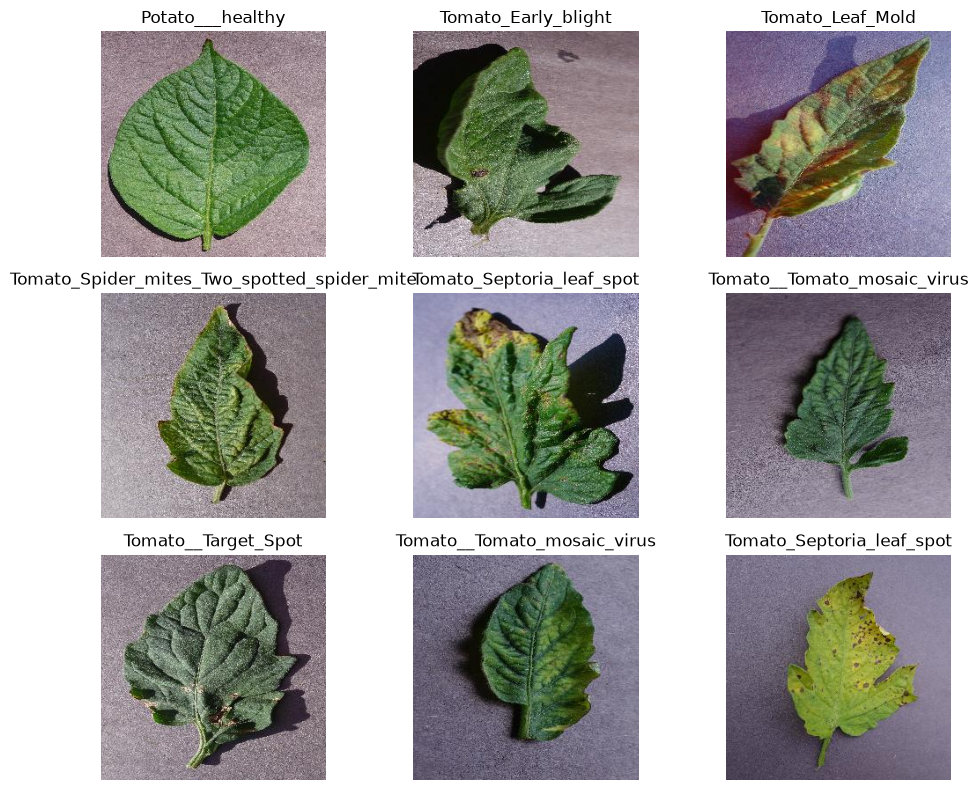

In [8]:
from PIL import Image
import random

fig, axes = plt.subplots(3, 3, figsize=(10, 8))

for ax in axes.flat:
    folder = random.choice(classes)

    images = []
    for file in folder.rglob("*"):
        if file.suffix.lower() in extensions:
            images.append(file)

    if images:
        img = Image.open(random.choice(images))
        ax.imshow(img)
        ax.set_title(folder.name)

    ax.axis("off")
    
plt.tight_layout()
plt.show()

## Class-wise image distribution

<Axes: xlabel='Images', ylabel='Class'>

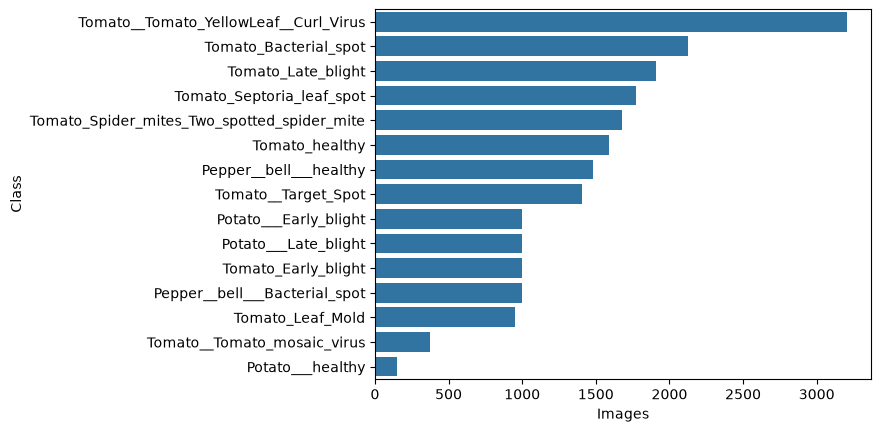

In [9]:
df_counts = pd.DataFrame(
    class_counts.items(),
    columns=["Class", "Images"]
)

df_counts = df_counts.sort_values("Images", ascending=False)

sns.barplot(data = df_counts, x= 'Images', y = 'Class')

## Image dimensions check

In [10]:
dimensions = []

for folder in classes:
    for file in folder.rglob("*"):
        if file.is_file() and file.suffix.lower() in extensions:
            with Image.open(file) as img:
                dimensions.append(img.size)

print("Unique dimensions:", len(set(dimensions)))
print("Sample dimensions:", dimensions[:10])

Unique dimensions: 1
Sample dimensions: [(256, 256), (256, 256), (256, 256), (256, 256), (256, 256), (256, 256), (256, 256), (256, 256), (256, 256), (256, 256)]


## Corrupt images check

In [11]:
corrupt_images = []

for folder in classes:
    for file in folder.rglob("*"):
        if file.is_file() and file.suffix.lower() in extensions:
            try:
                with Image.open(file) as img:
                    img.verify()
            except Exception:
                corrupt_images.append(file)

print("Corrupt images:", len(corrupt_images))

Corrupt images: 0


In [12]:
data = []

for folder in classes:
    for file in folder.rglob("*"):
        if file.is_file() and file.suffix.lower() in extensions:
            data.append({
                "image_path": str(file),
                "label": folder.name
            })

df = pd.DataFrame(data)

print(df.head())

                                          image_path  \
0  C:\Users\CORE COM\Desktop\DS\DL\PlantVillage\P...   
1  C:\Users\CORE COM\Desktop\DS\DL\PlantVillage\P...   
2  C:\Users\CORE COM\Desktop\DS\DL\PlantVillage\P...   
3  C:\Users\CORE COM\Desktop\DS\DL\PlantVillage\P...   
4  C:\Users\CORE COM\Desktop\DS\DL\PlantVillage\P...   

                           label  
0  Pepper__bell___Bacterial_spot  
1  Pepper__bell___Bacterial_spot  
2  Pepper__bell___Bacterial_spot  
3  Pepper__bell___Bacterial_spot  
4  Pepper__bell___Bacterial_spot  


In [13]:
print("Total Images:", df.value_counts().sum())
print("Total Classes:", df["label"].nunique())

print("\nClass Distribution:")
print(df["label"].value_counts())

Total Images: 20638
Total Classes: 15

Class Distribution:
label
Tomato__Tomato_YellowLeaf__Curl_Virus          3208
Tomato_Bacterial_spot                          2127
Tomato_Late_blight                             1909
Tomato_Septoria_leaf_spot                      1771
Tomato_Spider_mites_Two_spotted_spider_mite    1676
Tomato_healthy                                 1591
Pepper__bell___healthy                         1478
Tomato__Target_Spot                            1404
Potato___Early_blight                          1000
Potato___Late_blight                           1000
Tomato_Early_blight                            1000
Pepper__bell___Bacterial_spot                   997
Tomato_Leaf_Mold                                952
Tomato__Tomato_mosaic_virus                     373
Potato___healthy                                152
Name: count, dtype: int64


In [14]:
print(df.shape)
print(df.info())

(20638, 2)
<class 'pandas.DataFrame'>
RangeIndex: 20638 entries, 0 to 20637
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   image_path  20638 non-null  str  
 1   label       20638 non-null  str  
dtypes: str(2)
memory usage: 3.3 MB
None


In [15]:
X = df["image_path"]
y = df["label"]

In [16]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

In [17]:
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

In [18]:
print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

Training: 14446
Validation: 3096
Testing: 3096

Training class distribution:
label
Tomato__Tomato_YellowLeaf__Curl_Virus          2245
Tomato_Bacterial_spot                          1489
Tomato_Late_blight                             1336
Tomato_Septoria_leaf_spot                      1240
Tomato_Spider_mites_Two_spotted_spider_mite    1173
Tomato_healthy                                 1114
Pepper__bell___healthy                         1035
Tomato__Target_Spot                             983
Potato___Late_blight                            700
Tomato_Early_blight                             700
Potato___Early_blight                           700
Pepper__bell___Bacterial_spot                   698
Tomato_Leaf_Mold                                666
Tomato__Tomato_mosaic_virus                     261
Potato___healthy                                106
Name: count, dtype: int64


## Label Encoding

In [19]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

y_train_encoded = le.fit_transform(y_train)
y_val_encoded = le.transform(y_val)
y_test_encoded = le.transform(y_test)

print("Encoded labels:", y_train_encoded[:15])

Encoded labels: [ 3  1 13 10  3  7  8  8 13  1  6  7  5  9  9]


## Image preprocessing

In [20]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 16

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_image(
        image,
        channels=3
    )
    image.set_shape([None, None, 3])

    image = tf.image.resize(image, IMG_SIZE)
    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)

    return image, label

In [21]:
train_ds = tf.data.Dataset.from_tensor_slices(
    (X_train.values, y_train_encoded)
)

val_ds = tf.data.Dataset.from_tensor_slices(
    (X_val.values, y_val_encoded)
)

test_ds = tf.data.Dataset.from_tensor_slices(
    (X_test.values, y_test_encoded)
)

In [22]:
train_ds = train_ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
val_ds = val_ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
test_ds = test_ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)

train_ds = train_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
test_ds = test_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

In [23]:
for images, labels in train_ds.take(1):
    print("Image shape:", images.shape)
    print("Labels shape:", labels.shape)

Image shape: (16, 224, 224, 3)
Labels shape: (16,)


## CNN MODEL

In [24]:
def load_image_cnn(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0

    return image, label

In [25]:
train_cnn = tf.data.Dataset.from_tensor_slices(
    (X_train.values, y_train_encoded)
)

val_cnn = tf.data.Dataset.from_tensor_slices(
    (X_val.values, y_val_encoded)
)

test_cnn = tf.data.Dataset.from_tensor_slices(
    (X_test.values, y_test_encoded)
)

In [26]:
train_cnn = train_cnn.map(
    load_image_cnn,
    num_parallel_calls=tf.data.AUTOTUNE
).shuffle(1000).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

val_cnn = val_cnn.map(
    load_image_cnn,
    num_parallel_calls=tf.data.AUTOTUNE
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test_cnn = test_cnn.map(
    load_image_cnn,
    num_parallel_calls=tf.data.AUTOTUNE
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

In [27]:
for images, labels in train_cnn.take(1):
    print("Image shape:", images.shape)
    print("Minimum:", tf.reduce_min(images).numpy())
    print("Maximum:", tf.reduce_max(images).numpy())

Image shape: (16, 224, 224, 3)
Minimum: 0.0
Maximum: 0.9928973


In [ ]:
num_classes = len(le.classes_)

model = Sequential([
    Conv2D(32, (3, 3), activation="relu", input_shape=(224, 224, 3)),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    GlobalAveragePooling2D(),

    Dense(128, activation="relu"),
    Dropout(0.5),

    Dense(num_classes, activation="softmax")
])

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 15)             │         1,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,647 (115.81 KB)

 Trainable params: 29,647 (115.81 KB)

 Non-trainable params: 0 (0.00 B)

In [58]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [59]:
history = model.fit(
    train_cnn,
    validation_data=val_cnn,
    epochs=10
)

Epoch 1/10


c:\Users\CORE COM\Desktop\DS\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


903/903 ━━━━━━━━━━━━━━━━━━━━ 394s 433ms/step - accuracy: 0.2354 - loss: 2.3243 - val_accuracy: 0.3737 - val_loss: 1.9956
Epoch 2/10
903/903 ━━━━━━━━━━━━━━━━━━━━ 430s 476ms/step - accuracy: 0.4304 - loss: 1.7625 - val_accuracy: 0.5168 - val_loss: 1.4717
Epoch 3/10
903/903 ━━━━━━━━━━━━━━━━━━━━ 438s 484ms/step - accuracy: 0.5538 - loss: 1.3959 - val_accuracy: 0.6357 - val_loss: 1.1047
Epoch 4/10
903/903 ━━━━━━━━━━━━━━━━━━━━ 385s 426ms/step - accuracy: 0.6116 - loss: 1.1963 - val_accuracy: 0.6641 - val_loss: 0.9966
Epoch 5/10
903/903 ━━━━━━━━━━━━━━━━━━━━ 399s 441ms/step - accuracy: 0.6378 - loss: 1.0920 - val_accuracy: 0.7132 - val_loss: 0.8537
Epoch 6/10
903/903 ━━━━━━━━━━━━━━━━━━━━ 358s 396ms/step - accuracy: 0.6684 - loss: 1.0030 - val_accuracy: 0.7452 - val_loss: 0.7752
Epoch 7/10
903/903 ━━━━━━━━━━━━━━━━━━━━ 399s 441ms/step - accuracy: 0.6896 - loss: 0.9300 - val_accuracy: 0.7590 - val_loss: 0.7405
Epoch 8/10
903/903 ━━━━━━━━━━━━━━━━━━━━ 394s 436ms/step - accuracy: 0.7020 - loss: 0.89

### Accuracy graph of CNN model

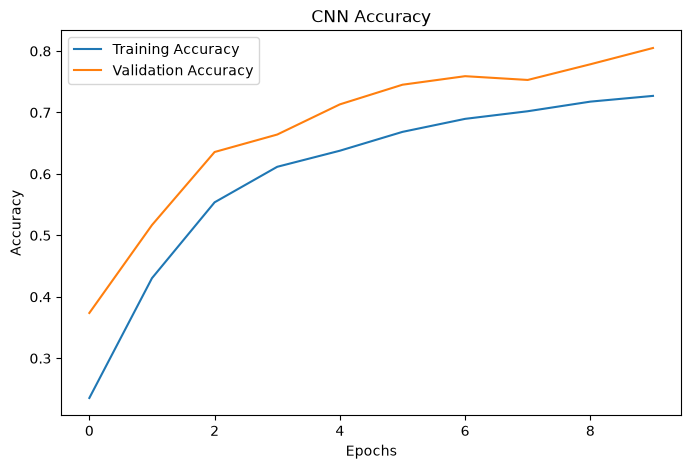

In [60]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("CNN Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

### Loss graph of CNN model

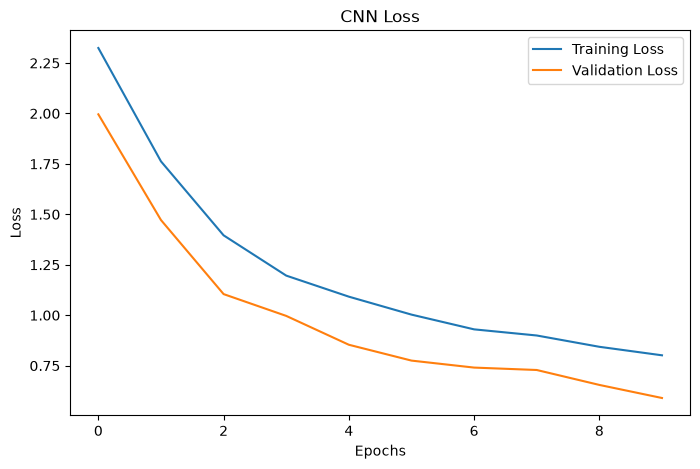

In [62]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("CNN Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

### Test evaluation

In [63]:
test_loss, test_accuracy = model.evaluate(test_cnn)

print("Test Accuracy:", test_accuracy)
print("Test Loss:", test_loss)

194/194 ━━━━━━━━━━━━━━━━━━━━ 18s 90ms/step - accuracy: 0.7991 - loss: 0.6036
Test Accuracy: 0.799095630645752
Test Loss: 0.6035937070846558


### Prediction

In [ ]:
y_pred_prob = model.predict(test_cnn)

y_pred = np.argmax(y_pred_prob, axis=1)

y_true = []

for images, labels in test_cnn:
    y_true.extend(labels.numpy())

y_true = np.array(y_true)

194/194 ━━━━━━━━━━━━━━━━━━━━ 18s 93ms/step


### Classification report

In [ ]:
print(classification_report(
    y_true,
    y_pred,
    target_names=le.classes_
))

                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       0.73      0.62      0.67       149
                     Pepper__bell___healthy       0.75      0.94      0.84       221
                      Potato___Early_blight       0.83      0.95      0.88       150
                       Potato___Late_blight       0.79      0.63      0.70       150
                           Potato___healthy       0.80      0.35      0.48        23
                      Tomato_Bacterial_spot       0.87      0.88      0.87       319
                        Tomato_Early_blight       0.65      0.36      0.46       150
                         Tomato_Late_blight       0.78      0.68      0.73       287
                           Tomato_Leaf_Mold       0.78      0.60      0.68       143
                  Tomato_Septoria_leaf_spot       0.73      0.82      0.77       266
Tomato_Spider_mites_Two_spotted_spider_mite       0.74      0.84

### Confusion matrix

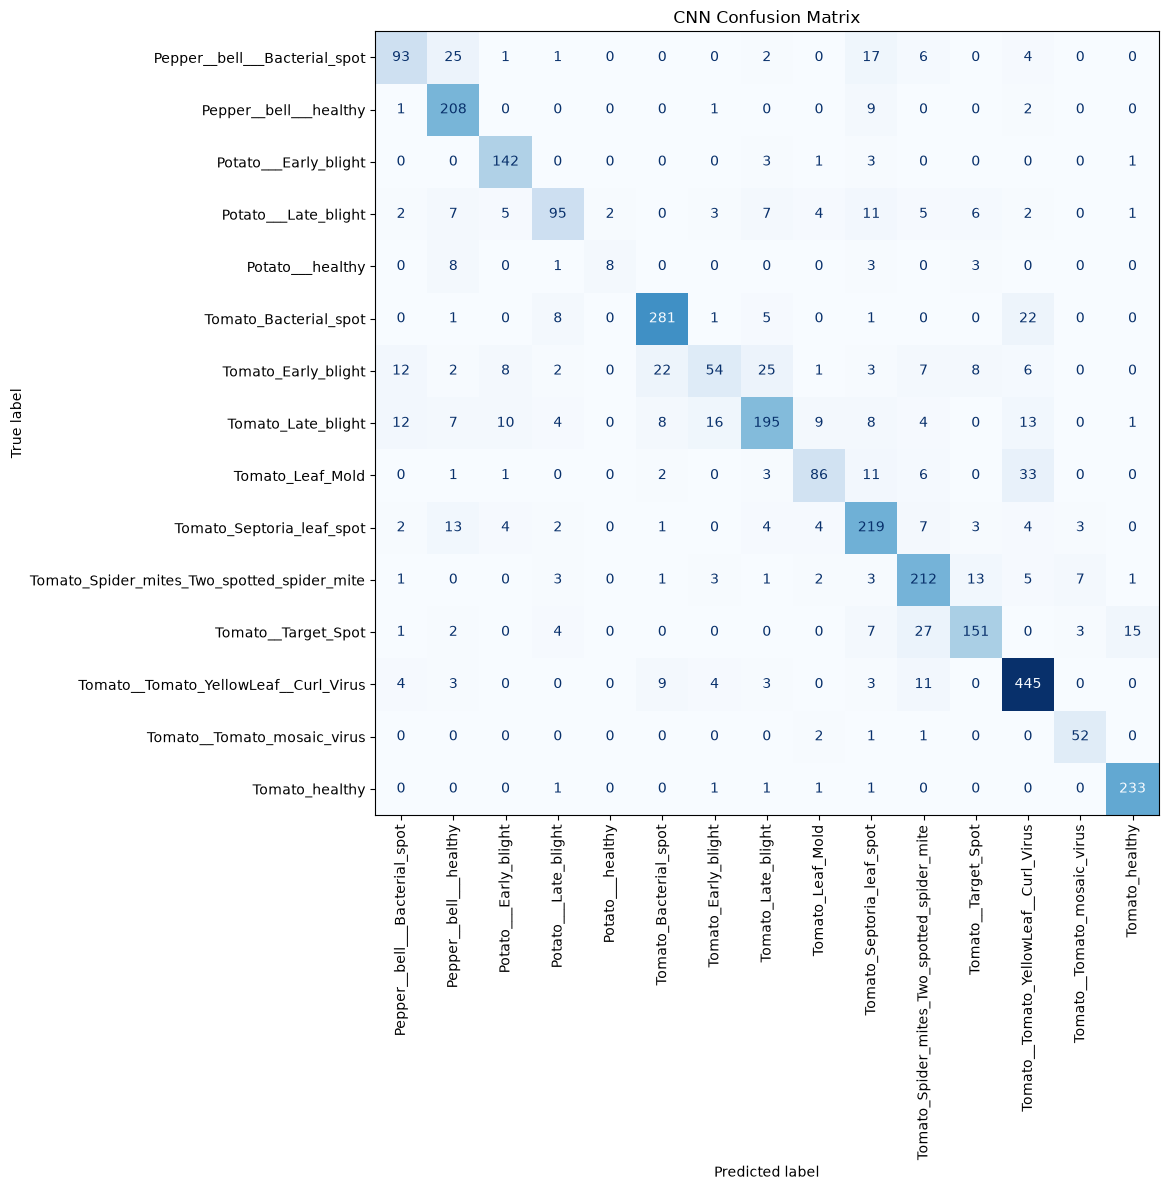

In [ ]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(14, 12))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=le.classes_
)

disp.plot(
    cmap="Blues",
    xticks_rotation=90,
    ax=plt.gca(),
    colorbar=False
)

plt.title("CNN Confusion Matrix")
plt.tight_layout()
plt.show()

### Saving CNN model

In [68]:
model.save("plant_disease_cnn.keras")

## Training MobileNetV2 model

### Load pretrained MobileNetV2

In [ ]:
base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 29s 3us/step


### Build MobileNetV2 model

In [ ]:
from tensorflow.keras.layers import (
    Input,
    GlobalAveragePooling2D,
    Dense,
    Dropout
)

inputs = Input(shape=(224, 224, 3))

x = base_model(inputs, training=False)

x = GlobalAveragePooling2D()(x)

x = Dropout(0.3)(x)

outputs = Dense(
    num_classes,
    activation="softmax"
)(x)

mobilenet_model = Model(inputs, outputs)

### Compile

In [71]:
mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

### Model Summary

In [72]:
mobilenet_model.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 15)             │        19,215 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,277,199 (8.69 MB)

 Trainable params: 19,215 (75.06 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### Train

In [73]:
history_mobilenet = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)

Epoch 1/5


c:\Users\CORE COM\Desktop\DS\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


903/903 ━━━━━━━━━━━━━━━━━━━━ 517s 566ms/step - accuracy: 0.7621 - loss: 0.7563 - val_accuracy: 0.8902 - val_loss: 0.3855
Epoch 2/5
903/903 ━━━━━━━━━━━━━━━━━━━━ 509s 563ms/step - accuracy: 0.8731 - loss: 0.3893 - val_accuracy: 0.9031 - val_loss: 0.3165
Epoch 3/5
903/903 ━━━━━━━━━━━━━━━━━━━━ 544s 603ms/step - accuracy: 0.8921 - loss: 0.3246 - val_accuracy: 0.9092 - val_loss: 0.2957
Epoch 4/5
903/903 ━━━━━━━━━━━━━━━━━━━━ 509s 564ms/step - accuracy: 0.8996 - loss: 0.2973 - val_accuracy: 0.9118 - val_loss: 0.2798
Epoch 5/5
903/903 ━━━━━━━━━━━━━━━━━━━━ 2188s 2s/step - accuracy: 0.9051 - loss: 0.2762 - val_accuracy: 0.9176 - val_loss: 0.2602


### Accuracy graph

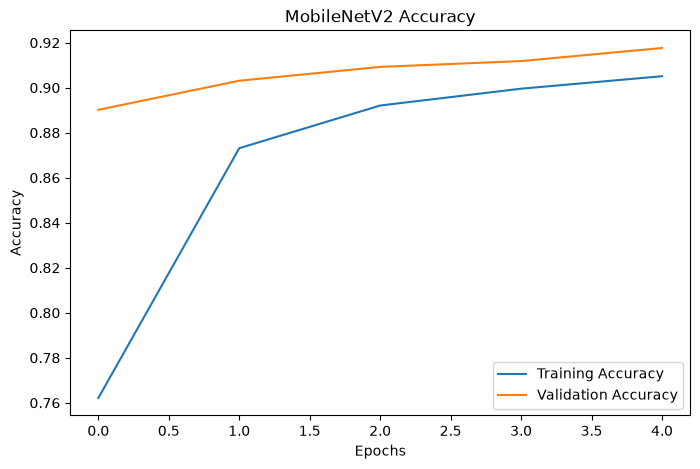

In [74]:
plt.figure(figsize=(8, 5))

plt.plot(history_mobilenet.history["accuracy"], label="Training Accuracy")
plt.plot(history_mobilenet.history["val_accuracy"], label="Validation Accuracy")

plt.title("MobileNetV2 Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

### Loss graph

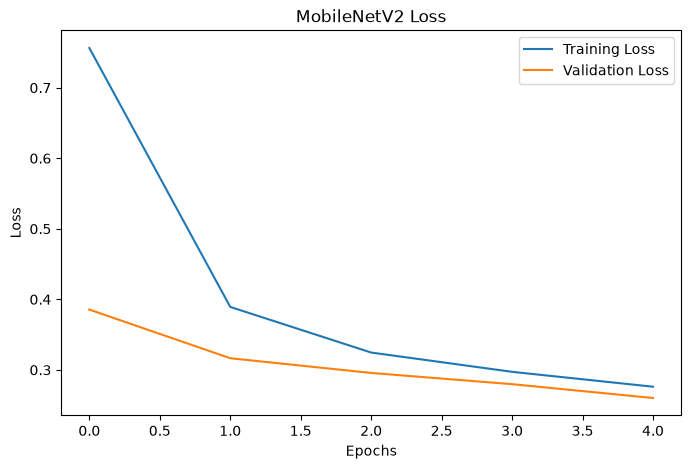

In [75]:
plt.figure(figsize=(8, 5))

plt.plot(history_mobilenet.history["loss"], label="Training Loss")
plt.plot(history_mobilenet.history["val_loss"], label="Validation Loss")

plt.title("MobileNetV2 Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

### Test evaluation

In [76]:
test_loss, test_accuracy = mobilenet_model.evaluate(test_ds)

print("Test Accuracy:", test_accuracy)
print("Test Loss:", test_loss)

194/194 ━━━━━━━━━━━━━━━━━━━━ 77s 394ms/step - accuracy: 0.9189 - loss: 0.2384
Test Accuracy: 0.9189276695251465
Test Loss: 0.2383892834186554


### Predictions

In [2]:
y_pred_prob = mobilenet_model.predict(test_ds)

y_pred = np.argmax(y_pred_prob, axis=1)

y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

NameError: name 'mobilenet_model' is not defined

### Classification report

In [ ]:
print(classification_report(
    y_true,
    y_pred,
    target_names=le.classes_
))

                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       0.96      0.97      0.97       149
                     Pepper__bell___healthy       1.00      0.97      0.99       221
                      Potato___Early_blight       0.99      0.97      0.98       150
                       Potato___Late_blight       0.86      0.97      0.91       150
                           Potato___healthy       1.00      0.87      0.93        23
                      Tomato_Bacterial_spot       0.89      0.96      0.92       319
                        Tomato_Early_blight       0.82      0.63      0.71       150
                         Tomato_Late_blight       0.94      0.91      0.93       287
                           Tomato_Leaf_Mold       0.92      0.83      0.88       143
                  Tomato_Septoria_leaf_spot       0.84      0.90      0.87       266
Tomato_Spider_mites_Two_spotted_spider_mite       0.87      0.93

### Confusion matrix

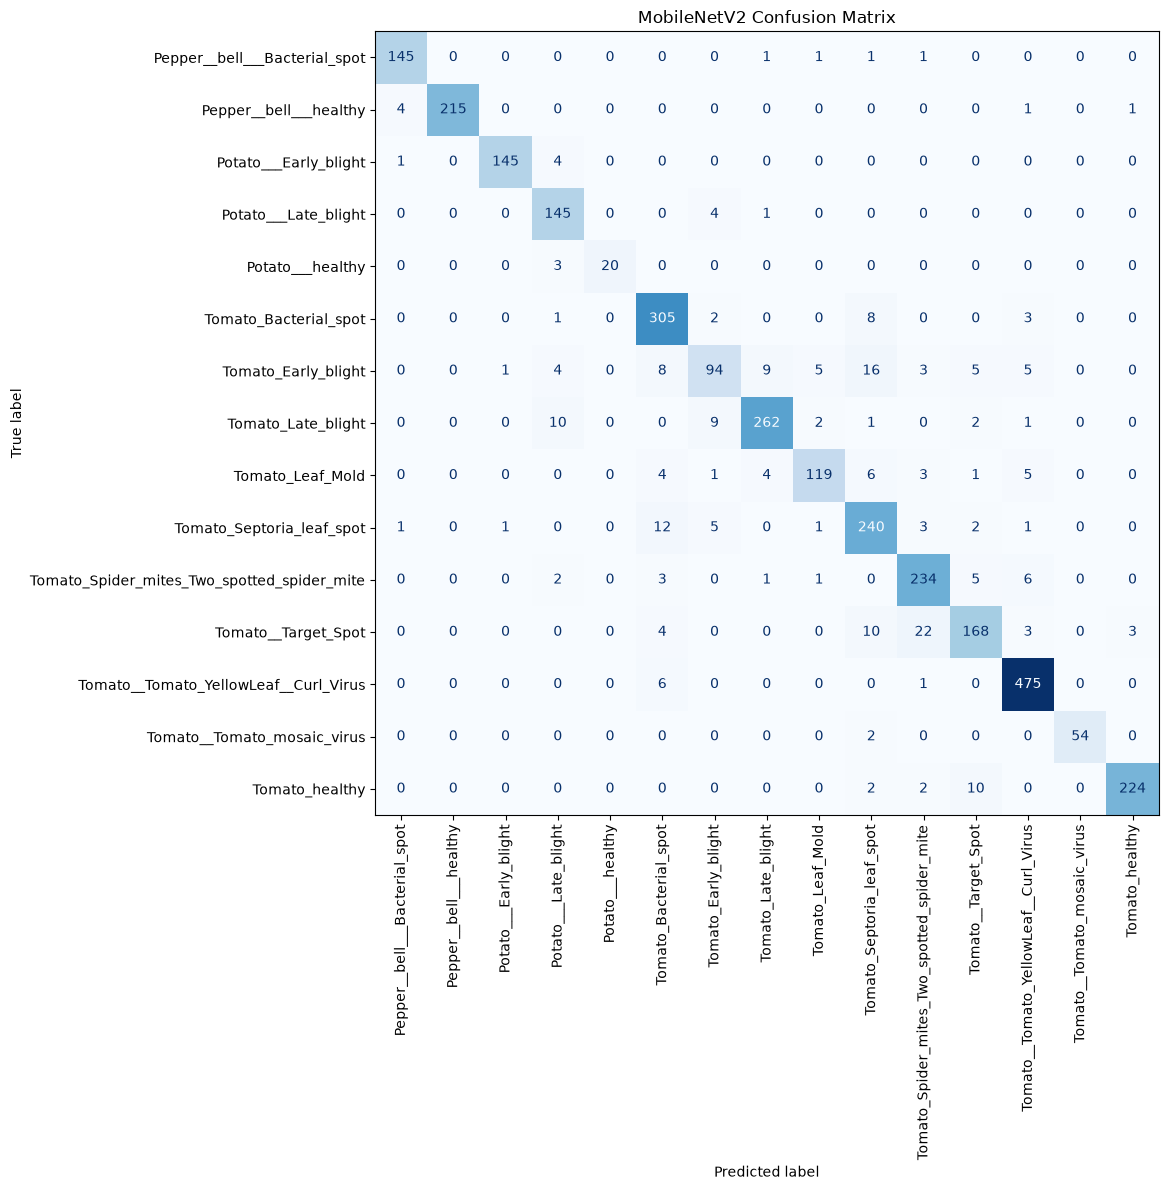

In [ ]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(14, 12))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=le.classes_
)

disp.plot(
    cmap="Blues",
    xticks_rotation=90,
    ax=plt.gca(),
    colorbar=False
)

plt.title("MobileNetV2 Confusion Matrix")
plt.tight_layout()
plt.show()

### Save model

In [80]:
mobilenet_model.save("plant_disease_mobilenetv2.keras")

# BOTH MODELS COMPARISION

In [28]:
model = tf.keras.models.load_model("plant_disease_cnn.keras")

mobilenet_model = tf.keras.models.load_model(
    "plant_disease_mobilenetv2.keras"
)

In [29]:
cnn_loss, cnn_accuracy = model.evaluate(test_cnn)

mobilenet_loss, mobilenet_accuracy = mobilenet_model.evaluate(test_ds)

print("CNN Accuracy:", cnn_accuracy)
print("MobileNetV2 Accuracy:", mobilenet_accuracy)

194/194 ━━━━━━━━━━━━━━━━━━━━ 20s 101ms/step - accuracy: 0.7991 - loss: 0.6036
194/194 ━━━━━━━━━━━━━━━━━━━━ 82s 396ms/step - accuracy: 0.9189 - loss: 0.2384
CNN Accuracy: 0.799095630645752
MobileNetV2 Accuracy: 0.9189276695251465


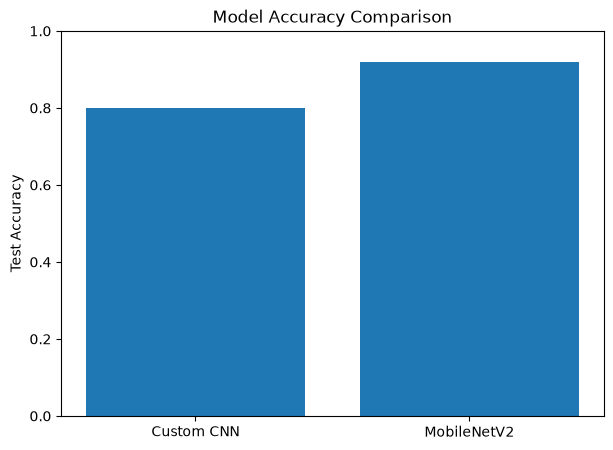

In [30]:
models = ["Custom CNN", "MobileNetV2"]

accuracies = [cnn_accuracy, mobilenet_accuracy]

plt.figure(figsize=(7, 5))

plt.bar(models, accuracies)

plt.title("Model Accuracy Comparison")
plt.ylabel("Test Accuracy")
plt.ylim(0, 1)

plt.show()

In [31]:
if mobilenet_accuracy > cnn_accuracy:
    print("MobileNetV2 performed better")
else:
    print("Custom CNN performed better")

MobileNetV2 performed better


In [ ]:
DATA_DIR = Path(r"C:\Users\CORE COM\Desktop\DS\DL\PlantVillage")
class_names = sorted(p.name for p in DATA_DIR.iterdir() if p.is_dir())
print(len(class_names), class_names[:5])

with open("class_names.json", "w") as f:
    json.dump(class_names, f)

model = tf.keras.models.load_model("plant_disease_mobilenetv2.keras")
print("Model outputs:", model.output_shape)  # last number should equal len(class_names)

15 ['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']
Model outputs: (None, 15)
